**Whisper** (Radford et al. 2023) a été entraîné sur environ 680 000 heures d'audio pour transcrire la parole. Son *encodeur* (la partie qui « écoute ») a donc surtout appris la *voix*, mais aussi à faire avec la *musique et les bruits de fond* présents dans ces enregistrements. Il se situe entre les modèles de sons généraux (AST, CLAP) et les modèles de voix du binôme (wav2vec2, HuBERT).

On utilise **`openai/whisper-base`** : seul l'encodeur sert (**21 M de paramètres**), modèle gelé.



Ce notebook :
1. extrait, pour chaque extrait, la représentation de chacune des *7 couches* de l'encodeur (moyenne sur la durée réelle du son) ;
2. cherche quelle couche contient le plus d'information sur l'émotion (choix sur le **dev**) ;
3. évalue le modèle retenu avec le classifieur commun ;
4. teste s'il complète AST, l'autre modèle de sons généraux (fusions audio uniquement).


## 0. Préparation

In [1]:
import sys
from pathlib import Path

if "google.colab" in sys.modules:
    from google.colab import drive
    drive.mount("/content/drive")
    CODE = Path("/content/drive/MyDrive/Projet Multimédia/Partie audio/ghislain")
else:
    CODE = next(p for p in [Path.cwd(), *Path.cwd().parents]
                if (p / "audio" / "ghislain" / "utils.py").exists()) / "audio" / "ghislain"
sys.path.insert(0, str(CODE))

import importlib
import utils
importlib.reload(utils)

P = utils.setup()            # audio + annotations

Mounted at /content/drive
Copie du zip depuis le Drive (~2-3 min)...
$ cp "/content/drive/MyDrive/Projet Multimédia/PROJET_SID_2026.zip" /content/PROJET_SID_2026.zip
Décompression de : audio, annotation
$ mkdir -p /content/data && unzip -q -o /content/PROJET_SID_2026.zip 'PROJET_SID_2026/movie/audio/*' 'PROJET_SID_2026/movie/annotation/*' -d /content/data
Données  : /content/data/PROJET_SID_2026
Résultats: /content/drive/MyDrive/Projet Multimédia/Partie audio/ghislain


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Test rapide : mettre par ex. 20 (extraits par ensemble). None = tous les extraits.
ECHANTILLON = None

meta = utils.load_metadata(P)
SUFFIXE = ""
if ECHANTILLON:
    meta = (pd.concat([meta[meta.split == s].sample(ECHANTILLON, random_state=utils.SEED)
                       for s in utils.SPLITS]).sort_values("video_id").reset_index(drop=True))
    SUFFIXE = "_echantillon"
tr, dv, te = (meta.split == s for s in utils.SPLITS)
y = meta.label.to_numpy()
print(len(meta), "extraits |", meta.split.value_counts().to_dict())

3088 extraits | {'train': 2207, 'dev': 442, 'test': 439}


## 1. Extraction des représentations de l'encodeur

Whisper découpe le son en trames de 20 ms (50 par seconde) et complète tout extrait jusqu'à **30 secondes** avec du silence. On ne fait donc la **moyenne que sur les trames qui correspondent au vrai son**, pour que ce silence ajouté ne dilue pas la représentation. On garde les 7 couches (entrée + 6 couches de l'encodeur), chacune de 512 nombres.

In [3]:
import torch
from transformers import WhisperFeatureExtractor, WhisperModel

MODEL_ID = "openai/whisper-base"
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
SR, BATCH = 16000, 16

extracteur = WhisperFeatureExtractor.from_pretrained(MODEL_ID)
encodeur = WhisperModel.from_pretrained(MODEL_ID).get_encoder().to(DEVICE).eval()
D = encodeur.config.d_model                                        # 512
N_COUCHES = encodeur.config.encoder_layers + 1                     # 7
TRAMES_MAX = encodeur.config.max_source_positions                  # 1500 trames = 30 s
print("Calcul sur", DEVICE, "| encodeur :", round(sum(p.numel() for p in encodeur.parameters()) / 1e6), "M",
      f"| {N_COUCHES} couches x {D}")


@torch.no_grad()
def vecteurs_whisper(chemins):
    sons = [utils.load_audio(c, SR)[: 30 * SR] for c in chemins]
    sortie = []
    for b in range(0, len(sons), BATCH):
        lot = sons[b:b + BATCH]
        x = extracteur(lot, sampling_rate=SR, return_tensors="pt").input_features.to(DEVICE)
        couches = torch.stack(encodeur(x, output_hidden_states=True).hidden_states, 1)   # (lot, 7, 1500, 512)
        for i, son in enumerate(lot):
            n = int(min(TRAMES_MAX, max(1, np.ceil(len(son) / SR * 50))))             # trames du vrai son
            sortie.append(couches[i, :, :n].mean(1).flatten().cpu().numpy())         # 7 x 512
    return np.stack(sortie)


Z = utils.extract_features("whisper_base" + SUFFIXE, meta, vecteurs_whisper, P)
couche = lambda l: Z[:, l * D:(l + 1) * D]
print("représentations :", Z.shape, "=", N_COUCHES, "couches x", D)

preprocessor_config.json:   0%|          | 0.00/185k [00:00<?, ?B/s]

config.json:   0%|          | 0.00/1.98k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  290MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/245 [00:00<?, ?it/s]

Calcul sur cpu | encodeur : 21 M | 7 couches x 512


extraction whisper_base:   0%|          | 0/16 [00:00<?, ?it/s]

représentations : (3088, 3584) = 7 couches x 512


## 2. Quelle couche contient le plus d'information sur l'émotion ?

On entraîne le classifieur commun sur chaque couche séparément et on compare le F1 macro sur le **dev** (le test n'est pas utilisé pour ce choix). On teste aussi la **moyenne des 7 couches**.

,couche,C,f1_macro_dev
0,0,0.001,0.214
1,1,0.001,0.243
2,2,0.010,0.264
3,3,0.000,0.246
4,4,0.001,0.261
5,5,0.003,0.299
6,6,0.003,0.290
7,moyenne,0.003,0.310


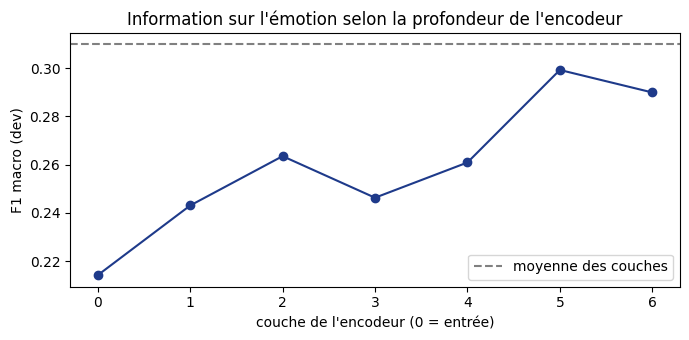

Représentation retenue (choisie sur le dev) : moyenne


In [4]:
scores = []
for l in range(N_COUCHES):
    _, C, s = utils.select_C(couche(l)[tr], y[tr], couche(l)[dv], y[dv])
    scores.append({"couche": l, "C": C, "f1_macro_dev": s.f1_macro_dev.max()})
X_moy = Z.reshape(len(Z), N_COUCHES, D).mean(1)
_, C, s = utils.select_C(X_moy[tr], y[tr], X_moy[dv], y[dv])
scores.append({"couche": "moyenne", "C": C, "f1_macro_dev": s.f1_macro_dev.max()})
scores = pd.DataFrame(scores)
display(scores.round(3))

fig, ax = plt.subplots(figsize=(7, 3.5))
ax.plot(range(N_COUCHES), scores.f1_macro_dev[:N_COUCHES], marker="o", color="#1e3a8a")
ax.axhline(scores.f1_macro_dev.iloc[-1], ls="--", color="gray", label="moyenne des couches")
ax.set(xlabel="couche de l'encodeur (0 = entrée)", ylabel="F1 macro (dev)",
       title="Information sur l'émotion selon la profondeur de l'encodeur")
ax.legend()
fig.tight_layout()
fig.savefig(P.FIGS / f"whisper_couches{SUFFIXE}.png", dpi=150)
plt.show()

meilleure = scores.loc[scores.f1_macro_dev.idxmax(), "couche"]
X_whisper = X_moy if meilleure == "moyenne" else couche(int(meilleure))
print("Représentation retenue (choisie sur le dev) :", meilleure)

## 3. Le modèle retenu avec le classifieur commun


=== whisper_enc (C = 0.003)
[whisper_enc | dev] F1 macro = 0.310 | acc. équilibrée = 0.319 | accuracy = 0.317
   F1 macro avec parole = 0.299 | sans parole = 0.210
   F1 par émotion : amusement 0.32, awe 0.28, contentment 0.29, excitement 0.32, anger 0.35, disgust 0.14, fear 0.35, sadness 0.45
[whisper_enc | test] F1 macro = 0.254 | acc. équilibrée = 0.258 | accuracy = 0.264
   F1 macro avec parole = 0.243 | sans parole = 0.169
   F1 par émotion : amusement 0.37, awe 0.14, contentment 0.24, excitement 0.18, anger 0.33, disgust 0.22, fear 0.35, sadness 0.20


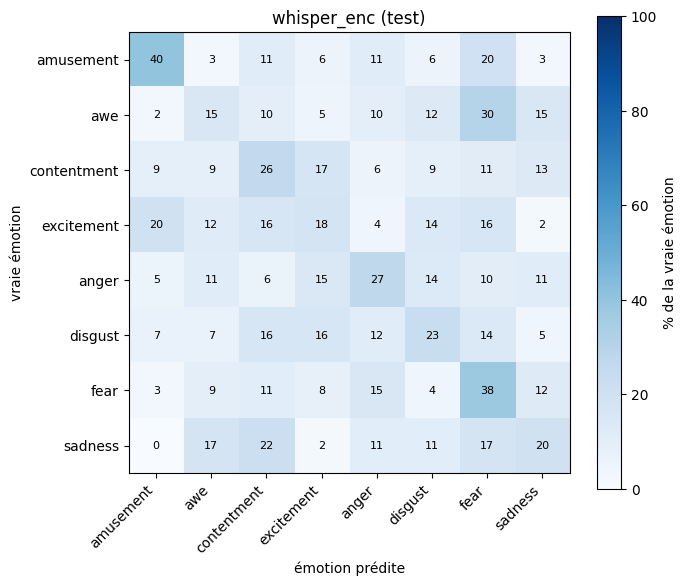

In [5]:
def evaluer(nom, X):
    clf, C, _ = utils.select_C(X[tr], y[tr], X[dv], y[dv])
    print(f"\n=== {nom} (C = {C})")
    probas = {}
    for split, m in (("dev", dv), ("test", te)):
        probas[split] = clf.predict_proba(X[m])
        utils.log_results(utils.evaluate(y[m], probas[split], meta.parole[m], nom, split), P)
        utils.save_preds(meta.video_id[m], probas[split], nom, split, P)
    return probas


p_whisper = evaluer("whisper_enc" + SUFFIXE, X_whisper)
utils.plot_confusion(y[te], p_whisper["test"], f"whisper_enc{SUFFIXE} (test)", P, f"cm_whisper_enc{SUFFIXE}_test.png")
plt.show()

## 4. L'encodeur de Whisper complète-t-il AST ?

AST a appris les **sons** (musique, bruitages) ; Whisper surtout la **voix**. On s'attend à ce qu'ils soient plus complémentaires qu'AST et CLAP. On teste :
- la **fusion précoce** : les deux vecteurs mis bout à bout (768 + 512 nombres) avant le classifieur ;
- la **fusion tardive** : la moyenne pondérée des probabilités des deux classifieurs, avec des poids choisis sur le **dev**.

In [6]:
X_ast = utils.load_features("ast" + SUFFIXE, P, meta.video_id.tolist())[:, :768]

p_ast = evaluer("ast" + SUFFIXE, X_ast)
evaluer("fus_precoce_ast_whisper" + SUFFIXE, np.hstack([X_ast, X_whisper]))

poids, f1_dev = utils.select_weights([p_ast["dev"], p_whisper["dev"]], y[dv])
print(f"\n=== fus_tardive_ast_whisper : poids AST {poids[0]} / Whisper {poids[1]} (F1 macro dev = {f1_dev:.3f})")
for split, m in (("dev", dv), ("test", te)):
    proba = utils.fuse([p_ast[split], p_whisper[split]], poids)
    utils.log_results(utils.evaluate(y[m], proba, meta.parole[m], "fus_tardive_ast_whisper" + SUFFIXE, split), P)
    utils.save_preds(meta.video_id[m], proba, "fus_tardive_ast_whisper" + SUFFIXE, split, P)


=== ast (C = 0.0001)
[ast | dev] F1 macro = 0.236 | acc. équilibrée = 0.253 | accuracy = 0.242
   F1 macro avec parole = 0.231 | sans parole = 0.175
   F1 par émotion : amusement 0.27, awe 0.23, contentment 0.15, excitement 0.22, anger 0.23, disgust 0.13, fear 0.31, sadness 0.35
[ast | test] F1 macro = 0.248 | acc. équilibrée = 0.269 | accuracy = 0.271
   F1 macro avec parole = 0.259 | sans parole = 0.175
   F1 par émotion : amusement 0.32, awe 0.14, contentment 0.23, excitement 0.19, anger 0.26, disgust 0.16, fear 0.46, sadness 0.22

=== fus_precoce_ast_whisper (C = 0.003)
[fus_precoce_ast_whisper | dev] F1 macro = 0.287 | acc. équilibrée = 0.299 | accuracy = 0.290
   F1 macro avec parole = 0.269 | sans parole = 0.246
   F1 par émotion : amusement 0.35, awe 0.34, contentment 0.24, excitement 0.26, anger 0.33, disgust 0.08, fear 0.31, sadness 0.39
[fus_precoce_ast_whisper | test] F1 macro = 0.251 | acc. équilibrée = 0.261 | accuracy = 0.262
   F1 macro avec parole = 0.245 | sans parol

## 5. Comparaison des trois modèles de sons généraux

f1_macro        f1_macro_avec_parole         \
split                        dev   test                  dev   test   
modele                                                                
hasard_stratifie           0.102  0.134                0.102  0.146   
ast                        0.236  0.248                0.231  0.259   
clap                       0.257  0.221                0.241  0.196   
whisper_enc                0.310  0.254                0.299  0.243   
fus_precoce_ast_whisper    0.287  0.251                0.269  0.245   
fus_tardive_ast_whisper    0.319  0.267                0.312  0.262   

                        f1_macro_sans_parole         
split                                    dev   test  
modele                                               
hasard_stratifie                       0.099  0.096  
ast                                    0.175  0.175  
clap                                   0.202  0.196  
whisper_enc                            0.210  0.169  
fus_precoce_ast_whisper                0.246  0.196  
fus_tardive_ast_whisper                0.222  0.173

F1 par émotion (test) :


,amusement,awe,contentment,excitement,anger,disgust,fear,sadness
modele,,,,,,,,
hasard_stratifie,0.05,0.08,0.09,0.15,0.25,0.10,0.17,0.18
ast,0.32,0.14,0.23,0.19,0.26,0.16,0.46,0.22
clap,0.35,0.13,0.23,0.17,0.24,0.07,0.40,0.19
whisper_enc,0.37,0.14,0.24,0.18,0.33,0.22,0.35,0.20
fus_precoce_ast_whisper,0.40,0.18,0.29,0.18,0.30,0.13,0.37,0.16
fus_tardive_ast_whisper,0.33,0.16,0.26,0.21,0.34,0.21,0.39,0.24


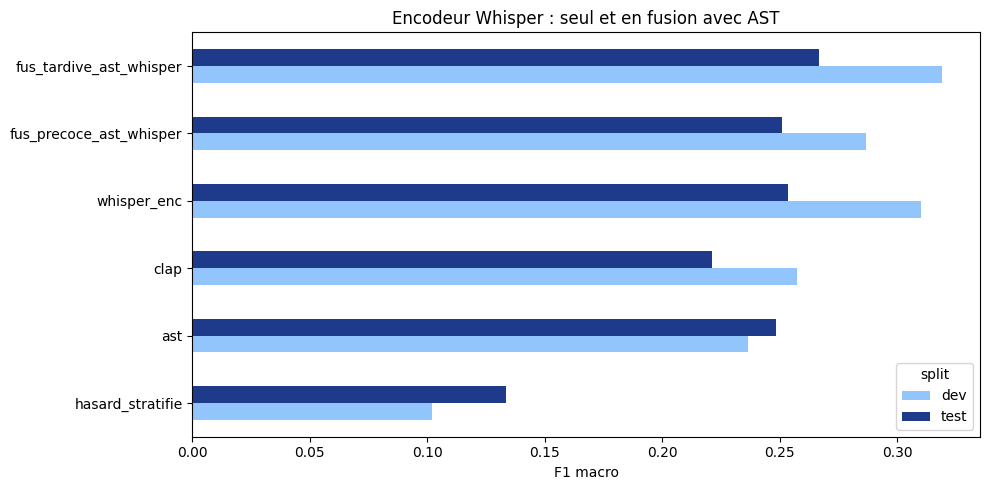

In [7]:
res = pd.read_csv(P.OUT / "resultats.csv")
noms = ["hasard_stratifie", "ast", "clap", "whisper_enc", "fus_precoce_ast_whisper", "fus_tardive_ast_whisper"]
noms = [n if n in ("hasard_stratifie", "clap") else n + SUFFIXE for n in noms]
noms = [n for n in noms if n in set(res.modele)]
tab = (res[res.modele.isin(noms)]
       .pivot_table(index="modele", columns="split",
                    values=["f1_macro", "f1_macro_avec_parole", "f1_macro_sans_parole"])
       .reindex(noms).round(3))
display(tab)

cols = [f"f1_{e}" for e in utils.EMOTIONS]
emo = res[(res.split == "test") & res.modele.isin(noms)].set_index("modele")[cols].reindex(noms)
emo.columns = utils.EMOTIONS
print("F1 par émotion (test) :")
display(emo.round(2))

fig, ax = plt.subplots(figsize=(10, 5))
f1 = res[res.modele.isin(noms)].pivot(index="modele", columns="split", values="f1_macro").reindex(noms)
f1[["dev", "test"]].plot.barh(ax=ax, color=["#93c5fd", "#1e3a8a"])
ax.set(xlabel="F1 macro", ylabel="", title="Encodeur Whisper : seul et en fusion avec AST")
fig.tight_layout()
fig.savefig(P.FIGS / f"whisper_comparaison{SUFFIXE}.png", dpi=150)
plt.show()

## 6. Conclusion

**Couches : l'information sur l'émotion augmente avec la profondeur de l'encodeur.**
- Le F1 macro sur le dev passe de **0,214** pour la couche d'entrée (couche 0) à **0,299** pour la couche 5, puis 0,290 pour la dernière couche (6).
- Les premières couches captent surtout le **son brut** (timbre, intensité) ; les dernières des informations plus **abstraites et proches de la parole** (manière de parler, mots). C'est dans ces dernières que se trouve le plus d'information sur l'émotion.
- La **moyenne des 7 couches** donne le meilleur résultat (**0,310**), ce qui montre que chaque niveau apporte une information un peu différente. C'est cette représentation qui est retenue (choix fait sur le dev).

**Whisper seul : le meilleur modèle de sons généraux sur le dev, et légèrement sur le test.**
- Sur le **dev**, l'encodeur de Whisper est nettement le meilleur des trois modèles (**0,310**, contre 0,236 pour AST et 0,257 pour CLAP).
- Sur le **test**, il retombe à **0,254**, juste au-dessus d'AST (0,248) et de CLAP (0,221). Cette baisse s'explique en partie par le fait que nous avons fait **beaucoup de choix sur le dev** (8 représentations × plusieurs valeurs de C), ce qui rend son score de dev un peu trop optimiste.
- Comme attendu pour un modèle entraîné sur la **parole**, Whisper est meilleur sur les extraits **avec parole** (0,299 en dev, 0,243 en test) que **sans parole** (0,210 et 0,169).
- Il reconnaît le mieux `amusement` (0,37), `fear` (0,35) et `anger` (0,33) sur le test, et le moins bien `awe` (0,14) et `excitement` (0,18).

**Fusion avec AST : un petit gain en fusion tardive, mais pas significatif.**
- **Fusion précoce AST + Whisper** : 0,287 sur le dev et **0,251** sur le test, soit à peu près le score de chaque modèle seul.
- **Fusion tardive AST + Whisper** (poids 0,5 / 0,5 choisis sur le dev) : **0,319** sur le dev et **0,267** sur le test. C'est le meilleur résultat **purement audio** de nos modèles de sons généraux sur le test.
- Le gain par rapport à AST seul (+0,019) et à Whisper seul (+0,013) reste **inférieur à la marge d'erreur** (environ ±0,03 à ±0,05) : on ne peut pas affirmer qu'il est réel.
- Sur le test, la fusion tardive progresse surtout pour `anger` (0,34), `sadness` (0,24) et `excitement` (0,21), mais recule pour `fear` (0,39 contre 0,46 pour AST seul).

**Bilan :** les trois modèles de sons généraux atteignent des scores proches (entre 0,22 et 0,31 selon le modèle et l'ensemble). Ils captent en grande partie la **même information** sur le son. La combinaison **AST + Whisper en fusion tardive** est notre meilleure configuration audio (0,267 sur le test), mais son avantage reste dans la marge d'erreur. Le point le plus intéressant de Whisper est qu'il montre que l'émotion se loge surtout dans les **couches profondes**, celles qui traitent la **parole**. Les modèles de voix du binôme pourraient donc être plus complémentaires d'AST que nos autres modèles de sons généraux.